In [8]:
# plan is to make a gaussian pulse which takes the system to the excited state and then to fit the data to a decaying exponential function and find the time it takes before the excited state possibility is down to 1/e
# I use the optimal omega0 and w found in part 4 to make the gaussian pulse that in 10ns takes the system to the excited state.
import numpy as np
from scipy.sparse import linalg as sla
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from myfunctions import powell_search, gaussian, rk4solve
from part2 import H_number, H_time
from part3 import Lindblad

## initialize the parameters for the simulation
E_c = 2*np.pi * 0.25   # rad/ns is E_c/h 0.25 GHz 50x smaller than E_j
E_j = 2*np.pi * 12.5   # rad/ns # same as before is E_j/h 12.5 GHz
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
t1, t2= 200, 150 # the relaxation and dephasing times in ns
gamma= 1.0 * np.array([1/t1,2 * (1/t2 - 1 / (2*t1))]) # the dissipation rates for the two levels
T1 = np.array([[0,1,0],[0,0,np.sqrt(2)],[0,0,0]],dtype=complex) # the lowering operator a on 3 levels
T2 = np.diag([0,1,2]) # adagger a 
T = np.array([T1,T2]) # the array of the two operators
T_g = 10 # gate time in ns
dT_g=0.005 # stepsize
rho0 = np.array([[1,0,0],[0,0,0],[0,0,0]],dtype=complex) # the initial density matrix
mu = T_g/2 # the amplitude is at its maximum at half of the gate time
sigma = T_g/6 # make sure it is close to zero in the start and end
omega0 = 2*np.pi *0.113491 # the amplitude of the drive in rad/ns found in part 4
H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
w = 2*np.pi * 4.750494 # The optimal w found in part 4.

H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
w = E[1]-E[0] # the energy gap between the x        ground state and the first excited state
A= U.T @ np.diag(N) @ U #the coupling term between the different states

def f(t,rho): # the function that will be used in the RK4 method to solve the Lindblad equation
    omega = omega0*gaussian(t,mu,sigma)
    H = H_time(t,H_0,A,omega,w)
    return Lindblad(T, rho, H, gamma)
t_L,C_L = rk4solve(f, rho0, 0, dT_g, T_g)
P1 = C_L[:, 1, 1].real

In [3]:
rho_final = C_L[-1] # the final density matrix after the gate time
T_final = 800 # the time after the gate time to see how the population of the first excited state decays
t_final = np.arange(T_g, T_final, dT_g)
def f(t,rho): # the function that will be used in the RK4 method to solve the Lindblad equation
    omega = omega0*gaussian(t,mu,sigma)
    H = H_time(t,H_0,A,omega,w)
    return Lindblad(T, rho, H, gamma)
t_Lf,C_Lf = rk4solve(f, rho0, 0, dT_g, T_final)

In [4]:
mask = t_Lf >= T_g
t_decay = t_Lf[mask]
P1_decay = C_Lf[:, 1, 1].real[mask]

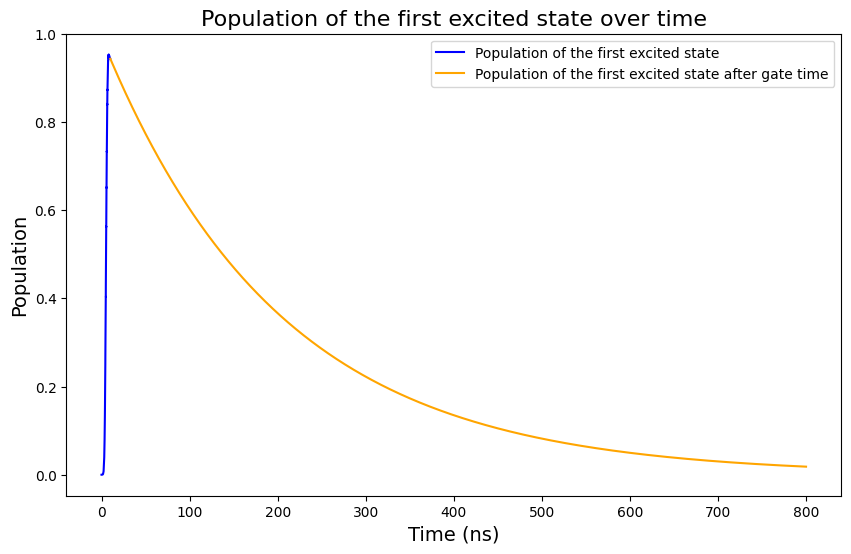

In [7]:
plt.figure(figsize=(10,6))
plt.plot(t_L, P1, label='Population of the first excited state', color='blue')
plt.plot(t_decay, P1_decay, label='Population of the first excited state after gate time', color='orange')
plt.title('Population of the first excited state over time', fontsize=16)
plt.xlabel('Time (ns)', fontsize=14)
plt.ylabel('Population', fontsize=14)
plt.legend()
plt.show()

In [33]:
def T1_fit(t, a, T1, b): # the function that will be used to fit the data to a decaying exponential function
    return a * np.exp(-t/T1) + b # b is because the population of the first excited state does not decay to zero.


In [34]:
A_guess = P1_decay[0] # the initial guess for the amplitude of the decaying exponential function
b_guess = 1 - A_guess # the initial guess for the offset of the decaying exponential function
P1_final = np.max(P1) * 1/np.exp(1) # the population of the first excited state after the gate time decays to 1/e of its maximum value
P1_f= abs(P1_decay- P1_final) # use absolute value so the minimum is the point closest to zero.
t_gamma = t_decay[np.argmin(P1_f)] - t_decay[0] # the time when the population of the first excited state is down to 1/e

In [35]:
p0 = [A_guess, t_gamma, b_guess] # initial guess for the parameters
par, cov = curve_fit(T1_fit, t_decay, P1_decay, p0=p0) # fit the model to the data

In [36]:
T1_fit_value = par[1] # the fitted value of T1

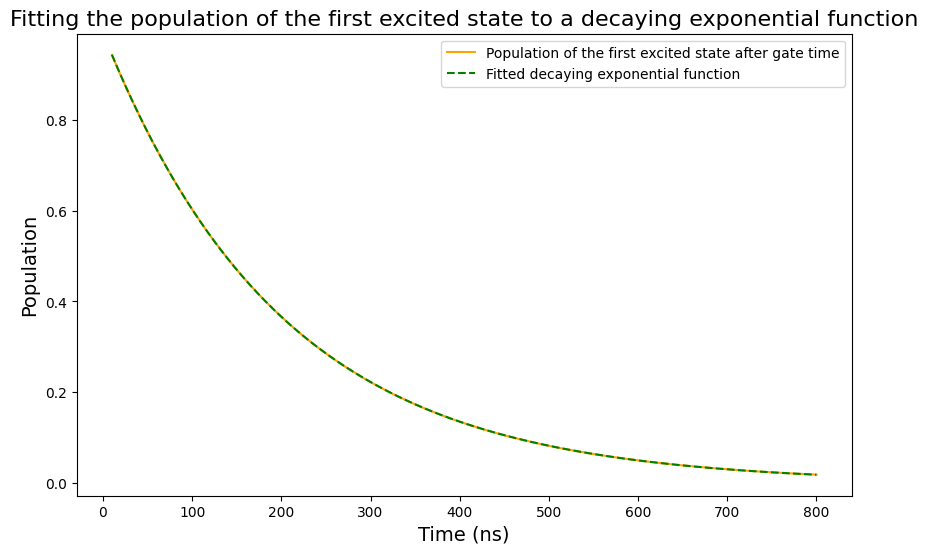

In [41]:
plt.figure(figsize=(10,6))
plt.plot(t_decay, P1_decay, label='Population of the first excited state after gate time', color='orange')
plt.plot(t_decay, T1_fit(t_decay, *par), label='Fitted decaying exponential function', color='green', linestyle='--')
plt.title('Fitting the population of the first excited state to a decaying exponential function', fontsize=16)
plt.xlabel('Time (ns)', fontsize=14)
plt.ylabel('Population', fontsize=14)   
plt.legend()
plt.show()

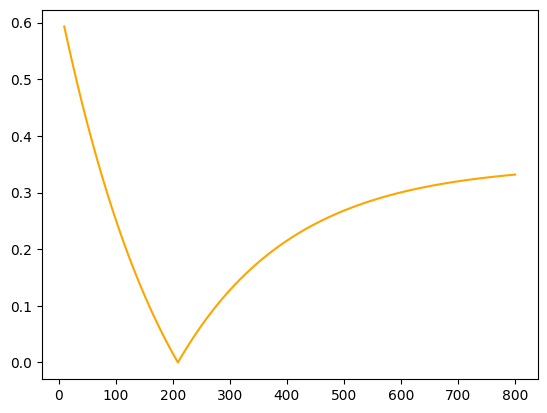

In [26]:
plt.plot(t_decay, P1_f, label='Population of the first excited state after gate time', color='orange')